In [50]:
from anemone.transforms import *
import torch

In [60]:
class Fourier(Hankel):
    """ A fourier transform for logarithmically sampled data. The implementation uses hankel transforms at the base.
        See Johansen and Sorensen 1979 - Fast Hankel Transforms eq.  87 + 88
    """
        
    def __init__(self, func, log10min=-20, log10max=10, smp_per_decade=10, omega_0=0.6221, device=None, range=None):
        def f1(lamda):
            return func(lamda/c.sqrt_twopi)/torch.sqrt(lamda)
        super().__init__(f1, -0.5, log10min, log10max, smp_per_decade, device, None, )
        self.lambda_included = False
        _, realfc = hankel_coefficients(-0.5, log10min, log10max, smp_per_decade, omega_0=omega_0)
        _, imagfc = hankel_coefficients( 0.5, log10min, log10max, smp_per_decade, omega_0=omega_0)
        imagfc = imagfc.to(self.fc.device)
        self.fc = torch.complex(realfc, -1*imagfc)
       

        if range is not None:
            self._recenter_function(range)
            self.create_interpolator(range[0], range[1])
    
    def f2r(self, f):
        """frequency to r"""
        return f*c.sqrt_twopi
    def r2f(self, r):
        """r to frequency"""
        return r/c.sqrt_twopi

    def range(self, fmin, fmax):
        rout, Resp = self._range(self.f2r(fmin), self.f2r(fmax))
        return self.r2f(rout), Resp*torch.sqrt(rout)
    
    def __call__(self, r):
        if isinstance(r, float): r = torch.tensor(r, device=self.device)
        rmax = r.max()
        rmin = r.min()
        if not 'interpfunc' in dir(self):
            self.r, self.resp = self.range(rmin, rmax)
            self.interpfunc = CubicSpline(self.r, self.resp, integrate=False, transform=torch.log10)
        r = r if isinstance(r, torch.Tensor) else torch.tensor(r, device=self.device)
        return self.interpfunc(r)



class invFourier(Fourier):
    def __init__(self, func, log10min=-30, log10max=20, smp_per_decade=10, device=None, range=None):
        super().__init__(func, log10min, log10max, smp_per_decade, device, None)
        self.lambda_included = False        
        self.fc = self.fc.real - 1j*self.fc.imag
        if range is not None:
            self._recenter_function(range)
            self.create_interpolator(range[0], range[1])
    def __repr__(self) -> str:
        return 'X(f)->x(t)'

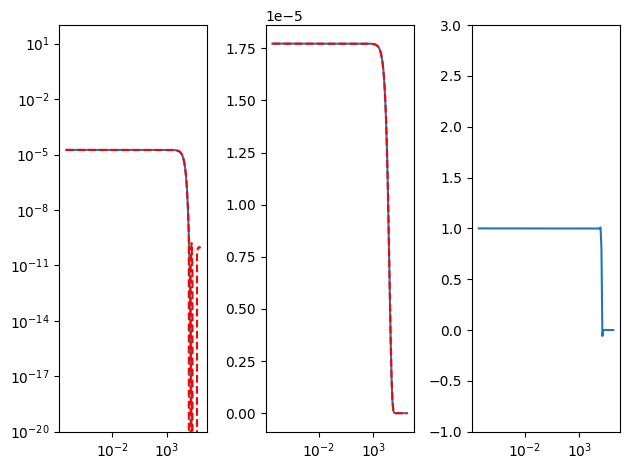

In [98]:

a = torch.tensor([1e10], dtype=torch.complex128)
def f1(x):
    return torch.exp(-a*x**2)

def F1(k):
    return torch.sqrt(c.pi/a)*torch.exp(-c.pi**2*k*k/a)

fc = torch.ones(1)*1e10


ft = Fourier(f1, smp_per_decade=12, omega_0 = 0.6221)
ft._recenter_function((fc,fc))
f,numeric = ft.range(1e-6,1e6)
analytic = F1(f)

f = f.numpy()
analytic = analytic.numpy()
numeric = numeric.numpy()
import matplotlib.pyplot as plt
fig,axs = plt.subplots(1,3)
axs[0].loglog(f, analytic)
axs[0].loglog(f, numeric, 'r--')
axs[1].semilogx(f, analytic)
axs[1].semilogx(f, numeric, 'r--')
axs[2].semilogx(f, analytic.real/numeric.real)
axs[0].set_ylim(1e-20, 1e2)
axs[-1].set_ylim(-1, 3)
plt.tight_layout()
plt.show()